# U02.E03 · Corpus público y clasificador de texto reproducible

**Asignatura:** INF-8239 Ciencia de Datos II
**Unidad:** 02 · Procesamiento de Lenguaje Natural
**Código:** U02.E03
**Dataset aprobado:** UCI Sentiment Labelled Sentences (Kotzias et al., KDD 2015) — CC BY 4.0

Este notebook integra, de manera ejecutable, las evidencias de LAB04 (corpus público validado) y
LAB05 (clasificador de texto reproducible). Reutiliza el código de `src/inf8239_u02/` en vez de
duplicar lógica: la fuente de verdad del preprocesamiento y los modelos vive en el paquete, no aquí.

Toda celda de este notebook debe ejecutarse en orden, con el dataset real ya descargado
(`uv run python scripts/download_data.py`) y el entorno sincronizado (`uv sync`).

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete inf8239_u02 aunque el notebook viva en notebooks/
SRC = Path.cwd().parent / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split

from inf8239_u02.config import ROOT, settings
from inf8239_u02.data import load_dataset, sha256, validate_dataframe
from inf8239_u02.modeling import build_models

print("ROOT:", ROOT)
print("DATA_SOURCE:", settings.data_source)
print("DATASET_PATH:", settings.dataset_path)

ROOT: C:\INF8239_U02_NLP_Proyecto_Base
DATA_SOURCE: url
DATASET_PATH: C:\INF8239_U02_NLP_Proyecto_Base\data\raw\dataset.csv


## Paso 1 · Carga y validación del dataset

Se reutiliza `load_dataset`/`validate_dataframe` de `inf8239_u02.data` — el mismo contrato que
usan las pruebas (`tests/test_data_contract.py`) y `scripts/train_text.py`, para que el notebook
no pueda divergir silenciosamente del resto del proyecto.

In [2]:
df = load_dataset().dropna(subset=[settings.text_column, settings.target_column])
df = df.drop_duplicates(subset=[settings.text_column]).reset_index(drop=True)
validate_dataframe(df, settings.text_column, settings.target_column)

print("Ruta:", settings.dataset_path)
print("SHA-256:", sha256(settings.dataset_path))
print("Filas y columnas:", df.shape)
df.head()

Ruta: C:\INF8239_U02_NLP_Proyecto_Base\data\raw\dataset.csv
SHA-256: 90995f55973a470ad7a67d9c34337ce1f4348dcb6bd5e08c6012c50ac6427a4f
Filas y columnas: (2982, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,negative,amazon
1,"Good case, Excellent value.",positive,amazon
2,Great for the jawbone.,positive,amazon
3,Tied to charger for conversations lasting more...,negative,amazon
4,The mic is great.,positive,amazon


## Paso 2 · Análisis exploratorio

Distribución de clases, distribución por dominio de origen (`source`: amazon/yelp/imdb) y
longitud de los textos. El dominio Yelp es el que corresponde al tema elegido para este
ejercicio ("reseñas o sentimiento de servicio").

Distribución de clases:
label
negative    0.500335
positive    0.499665
Name: proportion, dtype: float64

Distribución por dominio de origen:
source
imdb      996
yelp      996
amazon    990
Name: count, dtype: int64

Longitud de texto (caracteres):
count    2982.000000
mean       64.847418
std        43.897137
min         5.000000
50%        55.000000
90%       121.000000
99%       213.570000
max       477.000000
Name: text, dtype: float64


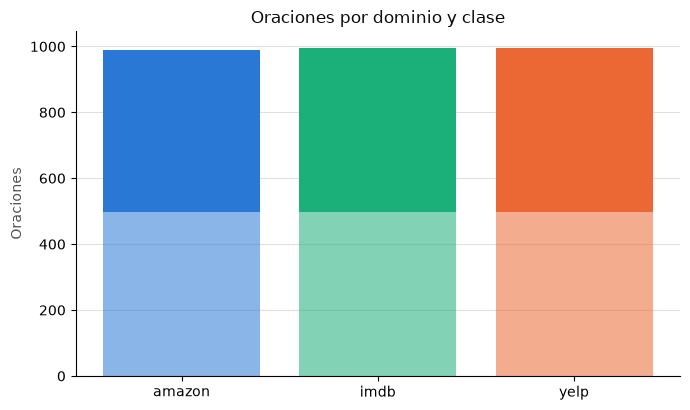

In [3]:
print("Distribución de clases:")
print(df[settings.target_column].value_counts(normalize=True))

print("\nDistribución por dominio de origen:")
print(df["source"].value_counts())

print("\nLongitud de texto (caracteres):")
print(df[settings.text_column].str.len().describe(percentiles=[0.5, 0.9, 0.99]))

# Colores categóricos fijos (paleta validada del proyecto, orden fijo por dominio)
PALETTE = {"amazon": "#2a78d6", "yelp": "#eb6834", "imdb": "#1baf7a"}
INK, SECONDARY, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

counts_by_source = df.groupby(["source", settings.target_column]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4.2))
x = range(len(counts_by_source))
bottom = [0] * len(counts_by_source)
for label in counts_by_source.columns:
    ax.bar(x, counts_by_source[label], bottom=bottom, label=label,
           color=[PALETTE.get(s, "#898781") for s in counts_by_source.index], alpha=0.55 if label == counts_by_source.columns[0] else 1.0)
    bottom = [b + v for b, v in zip(bottom, counts_by_source[label])]
ax.set_xticks(list(x))
ax.set_xticklabels(counts_by_source.index)
ax.set_ylabel("Oraciones", color=SECONDARY)
ax.set_title("Oraciones por dominio y clase", color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
reports = ROOT / "reports"
reports.mkdir(exist_ok=True)
plt.savefig(reports / "distribucion_por_dominio.png", dpi=170)
plt.show()

## Paso 3 · Partición train/test

Mismo protocolo que `scripts/train_text.py` (75/25, estratificado, `random_state` fijo desde
`.env`), para que los resultados del notebook y del script sean comparables. Se parte el
`DataFrame` completo (no solo texto/etiqueta) para conservar la columna `source` y poder
analizar el desempeño por dominio más adelante.

In [4]:
counts = df[settings.target_column].value_counts()
stratify = df[settings.target_column] if counts.min() >= 2 else None

train_df, test_df = train_test_split(
    df, test_size=0.25, random_state=settings.random_state, stratify=stratify,
)
x_train, y_train = train_df[settings.text_column], train_df[settings.target_column]
x_test, y_test = test_df[settings.text_column], test_df[settings.target_column]

print("Entrenamiento:", x_train.shape, " Prueba:", x_test.shape)

Entrenamiento: (2236,)  Prueba: (746,)


## Paso 4 · Entrenamiento y comparación de modelos

`build_models` (de `inf8239_u02.modeling`) entrega 3 pipelines: `dummy` (línea base ingenua),
`naive_bayes` (ComplementNB) y `logistic` (regresión logística balanceada). El vectorizador
TF-IDF vive **dentro** de cada pipeline para evitar fuga de información del conjunto de prueba
hacia el vocabulario de entrenamiento.

In [5]:
models = build_models(settings.random_state)
rows = []
predictions = {}

for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    predictions[name] = pred
    score = f1_score(y_test, pred, average="macro")
    rows.append({"model": name, "f1_macro": score})
    print(f"\n{name} · F1 macro={score:.3f}")
    print(classification_report(y_test, pred, zero_division=0))

metrics = pd.DataFrame(rows).sort_values("f1_macro", ascending=False)
metrics.to_csv(reports / "text_metrics.csv", index=False)
metrics


dummy · F1 macro=0.333
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67       373
    positive       0.00      0.00      0.00       373

    accuracy                           0.50       746
   macro avg       0.25      0.50      0.33       746
weighted avg       0.25      0.50      0.33       746




naive_bayes · F1 macro=0.819
              precision    recall  f1-score   support

    negative       0.82      0.81      0.82       373
    positive       0.81      0.83      0.82       373

    accuracy                           0.82       746
   macro avg       0.82      0.82      0.82       746
weighted avg       0.82      0.82      0.82       746




logistic · F1 macro=0.790
              precision    recall  f1-score   support

    negative       0.79      0.79      0.79       373
    positive       0.79      0.79      0.79       373

    accuracy                           0.79       746
   macro avg       0.79      0.79      0.79       746
weighted avg       0.79      0.79      0.79       746



,model,f1_macro
1,naive_bayes,0.819027
2,logistic,0.789541
0,dummy,0.333333


## Paso 5 · Modelo seleccionado y matriz de confusión

Se selecciona `logistic` como modelo de referencia (coherente con `scripts/train_text.py`) y se
presenta la matriz de confusión como evidencia visual real, no una captura de código.

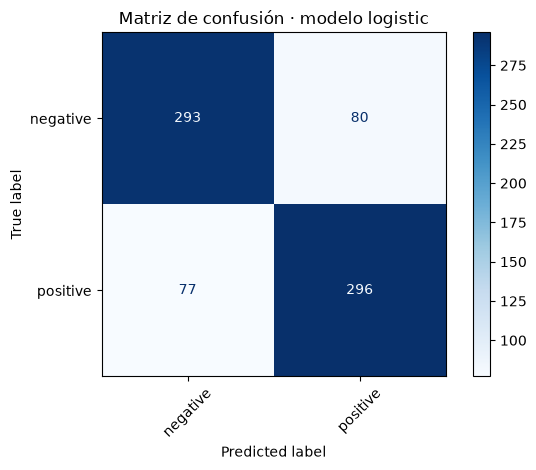

In [6]:
selected_name = "logistic"
selected_pred = predictions[selected_name]

ConfusionMatrixDisplay.from_predictions(y_test, selected_pred, xticks_rotation=45, cmap="Blues")
plt.title(f"Matriz de confusión · modelo {selected_name}")
plt.tight_layout()
plt.savefig(reports / "confusion_text.png", dpi=170)
plt.show()

## Paso 6 · Análisis de errores (acción manual pendiente)

Se exportan las oraciones mal clasificadas por el modelo seleccionado. **Esta celda NO
categoriza los errores** — eso requiere criterio humano. Abra `reports/error_analysis.csv` y
clasifique manualmente al menos 20 filas según la taxonomía del manual: negación, ironía,
ambigüedad, dialecto, texto insuficiente, etiqueta discutible, tema fuera de dominio.

In [7]:
errors = pd.DataFrame({
    "text": x_test,
    "source": test_df["source"],
    "real": y_test,
    "predicted": selected_pred,
})
errors = errors[errors["real"] != errors["predicted"]].copy()
errors["category"] = "REVISAR"
errors.to_csv(reports / "error_analysis.csv", index=False)

print(f"Errores encontrados: {len(errors)} de {len(y_test)} ({len(errors) / len(y_test):.1%})")
print("Pendiente: categorizar manualmente al menos 20 filas en reports/error_analysis.csv")
errors.head(10)

Errores encontrados: 157 de 746 (21.0%)
Pendiente: categorizar manualmente al menos 20 filas en reports/error_analysis.csv


,text,source,real,predicted,category
156,"Nice quality build, unlike some cheap s*** out...",amazon,positive,negative,REVISAR
2315,When my mom and I got home she immediately got...,yelp,negative,positive,REVISAR
639,"They do not last forever, but is not overly ex...",amazon,positive,negative,REVISAR
1804,"The acting, as you'd expect from this cast, is...",imdb,positive,negative,REVISAR
2824,"for 40 bucks a head, i really expect better food.",yelp,negative,positive,REVISAR
529,Unfortunately it's easy to accidentally activa...,amazon,negative,positive,REVISAR
1021,Waste your money on this game.,imdb,positive,negative,REVISAR
1915,The movie is not completely perfect but 'Titta...,imdb,positive,negative,REVISAR
2042,The Heart Attack Grill in downtown Vegas is an...,yelp,negative,positive,REVISAR
2234,The lighting is just dark enough to set the mood.,yelp,positive,negative,REVISAR


## Paso 7 · Desempeño por dominio

El tema elegido para este ejercicio es "reseñas o sentimiento de servicio": el dominio Yelp es
el que más se acerca (reseñas de restaurante/servicio). Se desglosa el F1 del modelo
seleccionado por dominio de origen para verificar si el desempeño es parejo o si el modelo
depende del estilo de alguno en particular.

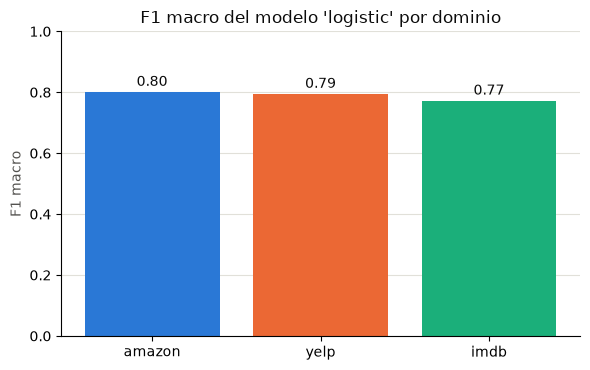

,source,f1_macro,n
0,amazon,0.800999,232
2,yelp,0.794544,268
1,imdb,0.772343,246


In [8]:
domain_rows = []
for source in sorted(test_df["source"].unique()):
    mask = (test_df["source"] == source).to_numpy()
    score = f1_score(y_test[mask], selected_pred[mask], average="macro")
    domain_rows.append({"source": source, "f1_macro": score, "n": int(mask.sum())})

domain_metrics = pd.DataFrame(domain_rows).sort_values("f1_macro", ascending=False)
domain_metrics.to_csv(reports / "text_metrics_por_dominio.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 3.8))
colors = [PALETTE.get(s, "#898781") for s in domain_metrics["source"]]
ax.bar(domain_metrics["source"], domain_metrics["f1_macro"], color=colors)
ax.set_ylim(0, 1)
ax.set_ylabel("F1 macro", color=SECONDARY)
ax.set_title(f"F1 macro del modelo '{selected_name}' por dominio", color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for i, row in domain_metrics.reset_index(drop=True).iterrows():
    ax.text(i, row["f1_macro"] + 0.02, f"{row['f1_macro']:.2f}", ha="center", color=INK)
plt.tight_layout()
plt.savefig(reports / "f1_por_dominio.png", dpi=170)
plt.show()

domain_metrics

## Paso 8 · Entorno de ejecución (reproducibilidad)

Huella del entorno donde se ejecutó este notebook, para poder explicar cualquier diferencia de
resultados frente a otra máquina.

In [9]:
import platform
import sklearn
import datetime

print("Fecha de ejecución:", datetime.datetime.now().isoformat(timespec="seconds"))
print("Python:", sys.version.split()[0])
print("Plataforma:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

Fecha de ejecución: 2026-10-17T09:27:16
Python: 3.12.15
Plataforma: Windows-11-10.0.26300-SP0
scikit-learn: 1.9.1
pandas: 2.3.3


## Paso 9 · Siguientes pasos

1. Abra `reports/error_analysis.csv` y categorice manualmente al menos 20 errores.
2. Corra `uv run pytest -q` para confirmar que las pruebas automatizadas siguen en verde.
3. Revise `reports/text_metrics.csv`, `reports/text_metrics_por_dominio.csv` y las figuras
   generadas en `reports/` — son la evidencia visual que exige el mandato de entrega.
4. Con estos resultados reales, se arma la síntesis de decisiones del PDF de entrega.